# Spot-to-trace alignment with jie

Multiplexed DNA-FISH first gives **detections**: spots with a decoded locus and a 3-D
position, but no link between the spots of one chromosome copy.  A cell typically has 1–7
candidate spots per locus (two homologs, sister chromatids after replication, false
detections), and some loci are missed.  `uchrom.im.trace.align_spots` decides which spots
form one chromatin fibre: it is an independent re-implementation of **jie** (Jia & Ren 2022,
*Nature Biotechnology*, doi:10.1038/s41587-022-01568-9).  For each (cell, chromosome) it
builds a graph over the candidate spots ordered along the genome, scores each link by a
Gaussian-chain polymer model (how plausible is this 3-D distance for this genomic distance?),
extracts the best path as one fibre, masks its spots and repeats — so the number of copies
(ploidy) comes out of the data — and finally groups fibres that stay close as sister
chromatids.  `uchrom.im.trace.score_alignment` compares the fibres with a reference assignment.

**Data**: Takei et al. 2021, *Nature* 590:344 — raw DNA seqFISH+ detections of E14 mouse ES
cells at 25 kb (Zenodo [3735329](https://zenodo.org/records/3735329), `DNAseqFISH+.zip`,
144 MB; replicate 1: 201 cells, 20 chromosomes × 60 loci, 316,995 spots).
`ds.load("takei2021_mesc_detections")` builds them once with `uchrom.io.read_seqfish_detections`.
The raw files number the loci (`regionID` 1–60 per chromosome) without genomic coordinates; the
loader takes the mm10 locus of each from the same experiment's *traced* table, the 4DN FOF-CT
file `4DNFIHF3JCBY` (22 MB; see `import_fofct.ipynb`), which section 5 also uses as the
reference (`ds.load("takei2021_mesc")`).  **Runtime**: about a minute (all chromosomes).

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from uchrom.im.trace import SpotAlignerParams, align_spots, score_alignment
import uchrom.datasets as ds
import uchrom.fea as fea

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

det = ds.load("takei2021_mesc_detections")      # raw detections (Zenodo 3735329), built once
print(det)

ChromData: n_spots=316995, n_traces=4018, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'spot_id', 'fov', 'channel', 'region', 'label', 'bin_id']
  cells:   ['fov'] (201 cells)
  spot_tracks:    ['dot_intensity', 'chr1_intensity', 'chr2_intensity', 'chr3_intensity', 'chr4_intensity', 'chr5_intensity', 'chr6_intensity', 'chr7_intensity', 'chr8_intensity', 'chr9_intensity', 'chr10_intensity', 'chr11_intensity', 'chr12_intensity', 'chr13_intensity', 'chr14_intensity', 'chr15_intensity', 'chr16_intensity', 'chr17_intensity', 'chr18_intensity', 'chr19_intensity', 'chrX_intensity']
  uns:     ['xyz_unit', 'voxel_nm', 'source', 'genome_assembly', 'locus_map', 'dataset']


## 1. The raw detections

The zip holds eight tables (1 Mb and 25 kb loci, several replicates); the loader read the 25-kb
replicate 1 straight from it: one spot per detection (`spot_id` = its row in the file),
`cell_id` = `<fov>_<cellID>` (`cellID` is numbered within each FOV), the locus index as the
spot column `region`, positions in nm (103-nm pixels, 250-nm z-steps; `uns["xyz_unit"]`) and the
intensities as `spot_tracks`.  Nothing is traced yet: a trace of this object is a *candidate
set* — all detections of one chromosome in one cell.  The spot column `label` is the upstream
pipeline's homolog call (`labelID`: 0, 1; rarely 2, 3; −1 = rejected); we keep it as the
reference and never show it to the aligner.

In [2]:
sp = det.spots
per_locus = sp.groupby(["cell_id", "chrom", "bin_id"], observed=True).size()
print(f"{det.n_spots:,} detections, {sp['cell_id'].nunique()} cells in {sp['fov'].nunique()} FOVs, "
      f"{sp['chrom'].nunique()} chromosomes x {sp['region'].nunique()} loci")
print("candidate spots per (cell, chromosome, locus):", per_locus.value_counts().sort_index().to_dict())
print("upstream label:", sp["label"].value_counts().sort_index().to_dict())
det.to_dataframe().join(det.spot_tracks[["dot_intensity"]])[
    ["spot_id", "cell_id", "chrom", "region", "start", "x", "y", "z", "dot_intensity", "label"]].head()

316,995 detections, 201 cells in 5 FOVs, 20 chromosomes x 60 loci
candidate spots per (cell, chromosome, locus): {1: 93313, 2: 77662, 3: 18664, 4: 2740, 5: 251, 6: 24, 7: 1}
upstream label: {-1: 2487, 0: 171962, 1: 140231, 2: 2240, 3: 75}


,spot_id,cell_id,chrom,region,start,x,y,z,dot_intensity,label
0,0,0_1,chr1,2,135625000,176998.413188,15131.656798,2820.508940,638,0
1,1,0_1,chr1,3,135650000,176952.611457,15055.710912,2770.752832,738,0
2,2,0_1,chr1,3,135650000,165262.565996,21032.173096,2931.377597,223,1
3,3,0_1,chr1,5,135700000,176964.997928,15131.178147,2590.770663,775,0
4,4,0_1,chr1,5,135700000,164877.434061,21106.379765,3283.300545,787,1


The 4DN FOF-CT table `4DNFIHF3JCBY` deposits exactly these detections after tracing: the loader
matched the spots by position (pixels × voxel size = µm, 3 decimals) and recorded the check in
`uns["locus_map"]` — every detection matched, the same cell ids, the trace suffix equal to
`label` — and gave each (chromosome, `regionID`) its mm10 locus, the locus axis `bins`.

In [3]:
print(det.uns["locus_map"])
print(f"{det.n_bins} (chromosome, regionID) -> mm10 loci, e.g.",
      det.to_dataframe().iloc[0][["chrom", "region", "start", "end"]].to_dict())

{'source': '4DN 4DNFIHF3JCBY (FOF-CT) matched by position', 'matched': 316995, 'detections': 316995, 'same_cell': 1.0, 'label_equals_fofct_homolog': 1.0, 'loci': 1200}
1200 (chromosome, regionID) -> mm10 loci, e.g. {'chrom': 'chr1', 'region': 2, 'start': 135625000, 'end': 135650000}


## 2. The `align_spots` input

`align_spots` takes the detections as a `ChromData` — any object whose spots carry `cell_id`;
its traces are ignored — or as a table with `cell_id, chrom, start, end, x, y, z` in **nm**
(optional `sigma_x/y/z` localisation errors and a `spot_id`).  It aligns each (cell, chromosome)
on its own (`chrom=` / `cells=` restrict it), works in nm (converted from `uns["xyz_unit"]`),
and returns a new `ChromData` that keeps the input's locus axis, cells, `uns`, coordinate unit,
spot columns (`spot_id`, `label`, …) and spot tracks.  Several spots may share a
(cell, locus) — resolving them is the job.

## 3. One chromosome first: what the parameters do

On chr19 (15,000 detections in 201 cells) compare the defaults with settings suited to this
data, scoring each run against `label` with `score_alignment` (spots with `label ≥ 0`, of the
chromosomes aligned):

* **assigned** — fraction of labelled spots placed on some fibre;
* **purity** — per called fibre, the fraction of its spots from its majority `label`;
* **ARI** — per cell, adjusted Rand index between fibres and `label` (median over cells).

The default `max_skip=3` lets a path jump over at most 3 undetected loci; with ~35 % of
loci missed per copy, paths break and most spots stay unassigned.  Allowing longer skips
(`max_skip=12`) with a larger per-skip penalty, at least 10 spots per fibre, at most 4
fibres per (cell, chromosome), and rejecting paths whose mean link cost exceeds 8 assigns
most spots.  We chose these on chr19 by this comparison — a calibration against the
reference, so the genome-wide run below is the fairer test.  The scale factor τ (nm per bp)
is fitted per chromosome from the data unless you pass `tau_by_chrom`.

In [4]:
TUNED = SpotAlignerParams(max_skip=12, gap_penalty=5.0, min_spots_per_fiber=10, max_fibers_per_chrom=4,
                          mean_edge_weight_cutoff=8.0, sister_pair_radius_nm=400.0)
rows = {}
for name, params in [("defaults", SpotAlignerParams()), ("tuned", TUNED)]:
    t0 = time.perf_counter()
    res = align_spots(det, chrom="chr19", params=params)
    rows[name] = score_alignment(res, det, label="label")[["assigned", "purity", "median ARI"]]
    rows[name]["fibres per (cell, chr)"] = res.results["ploidy"]["n_fibers"].mean()
    rows[name]["seconds"] = time.perf_counter() - t0
print("fitted tau:", {c: round(v["tau_nm_per_bp"], 4) for c, v in res.uns["jie_polymer"].items()}, "nm/bp")
pd.DataFrame(rows).round(3)

fitted tau: {'chr19': 0.0074} nm/bp


,defaults,tuned
assigned,0.576,0.828
purity,0.863,0.977
median ARI,0.424,0.721
"fibres per (cell, chr)",1.254,1.856
seconds,3.931,15.486


## 4. All chromosomes

The aligner works per (cell, chromosome), so the genome-wide run is the same call on all
detections (~4,000 graphs).  It returns a `ChromData`: `spots` (the kept detections with their
`trace_id` — the fibre — and the input's spot columns), `traces` (one row per fibre: cell,
chromosome, number of spots, path cost, sister group), `results['ploidy']` (fibres and sister
groups per (cell, chromosome)) and `uns['jie_polymer']` (the fitted τ per chromosome).

In [5]:
t0 = time.perf_counter()
cd = align_spots(det, params=TUNED)
print(f"aligned in {time.perf_counter() - t0:.0f} s\n")
print(cd)
cd.traces.head()

aligned in 87 s

ChromData: n_spots=270451, n_traces=7515, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'spot_id', 'fov', 'channel', 'region', 'label', 'bin_id']
  cells:   ['fov'] (201 cells)
  spot_tracks:    ['dot_intensity', 'chr1_intensity', 'chr2_intensity', 'chr3_intensity', 'chr4_intensity', 'chr5_intensity', 'chr6_intensity', 'chr7_intensity', 'chr8_intensity', 'chr9_intensity', 'chr10_intensity', 'chr11_intensity', 'chr12_intensity', 'chr13_intensity', 'chr14_intensity', 'chr15_intensity', 'chr16_intensity', 'chr17_intensity', 'chr18_intensity', 'chr19_intensity', 'chrX_intensity']
  traces:  ['trace_id', 'cell_id', 'chrom', 'n_spots', 'path_weight', 'mean_edge', 'sister_group'] (7515 traces)
  results: ['ploidy']
  uns:     ['xyz_unit', 'voxel_nm', 'source', 'genome_assembly', 'locus_map', 'dataset', 'jie_polymer', 'jie_params']


,trace_id,cell_id,chrom,n_spots,path_weight,mean_edge,sister_group
0,0,0_1,chr1,37,100.762165,2.651636,0
1,1,0_1,chr1,32,122.095657,3.699868,1
2,2,0_1,chr10,39,94.118443,2.352961,2
3,3,0_1,chr10,37,113.078246,2.975743,3
4,4,0_1,chr11,33,69.845648,2.054284,4


In [6]:
ploidy = cd.results["ploidy"]
per_chrom = score_alignment(cd, det, label="label", per="chrom")
per_chrom = per_chrom.loc[sorted(per_chrom.index, key=lambda c: (c == "chrX", len(c), c)),
                          ["assigned", "purity", "median ARI"]]
per_chrom["2 fibres"] = ploidy.groupby("chrom")["n_fibers"].apply(lambda n: (n == 2).mean())
auto = per_chrom.drop(index="chrX")
print(f"autosomes: {auto['assigned'].mean():.1%} of labelled spots assigned, purity {auto['purity'].mean():.3f}, "
      f"median ARI {auto['median ARI'].mean():.2f}, two fibres in {auto['2 fibres'].mean():.0%} of (cell, chromosome)")
print(f"chrX     : one fibre in {(ploidy.loc[ploidy['chrom'] == 'chrX', 'n_fibers'] == 1).mean():.0%} of cells (E14 is male)")
rejected = det.spots.loc[det.spots["label"] < 0, "spot_id"]
print(f"rejected detections (label = -1) placed on a fibre: {np.isin(rejected, cd.spots['spot_id']).mean():.0%}")
per_chrom.round(3).head()

autosomes: 86.3% of labelled spots assigned, purity 0.993, median ARI 0.80, two fibres in 88% of (cell, chromosome)
chrX     : one fibre in 93% of cells (E14 is male)
rejected detections (label = -1) placed on a fibre: 28%


,assigned,purity,median ARI,2 fibres
chr1,0.856,0.997,0.785,0.896
chr2,0.880,0.991,0.838,0.866
chr3,0.851,0.994,0.774,0.905
chr4,0.897,0.998,0.870,0.945
chr5,0.887,0.997,0.856,0.840


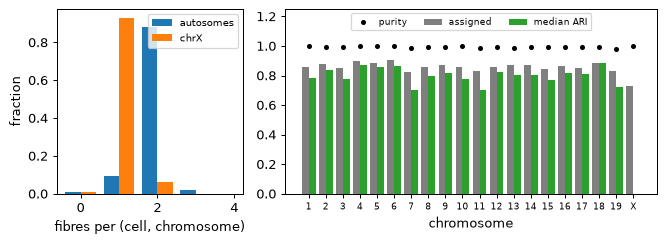

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8), gridspec_kw={"width_ratios": [1, 2]})
for chroms, name, colour in [(ploidy["chrom"] != "chrX", "autosomes", "tab:blue"),
                             (ploidy["chrom"] == "chrX", "chrX", "tab:orange")]:
    vc = ploidy.loc[chroms, "n_fibers"].value_counts(normalize=True).sort_index()
    axes[0].bar(vc.index + (0.2 if name == "chrX" else -0.2), vc.values, width=0.4, color=colour, label=name)
axes[0].set_xlabel("fibres per (cell, chromosome)"); axes[0].set_ylabel("fraction"); axes[0].legend(fontsize=8)
x = np.arange(len(per_chrom))
axes[1].bar(x - 0.2, per_chrom["assigned"], width=0.4, label="assigned", color="tab:gray")
axes[1].bar(x + 0.2, per_chrom["median ARI"].fillna(0), width=0.4, label="median ARI", color="tab:green")
axes[1].plot(x, per_chrom["purity"], "k.", label="purity")
axes[1].set_xticks(x, [c.replace("chr", "") for c in per_chrom.index], fontsize=7)
axes[1].set_ylim(0, 1.25); axes[1].set_xlabel("chromosome"); axes[1].legend(fontsize=7, ncol=3, loc="upper center")
plt.tight_layout(); plt.show()

jie recovers the deposited assignment from geometry alone: almost every called fibre comes
from one upstream homolog (purity ≈ 0.99), most labelled spots are placed, and the expected
karyotype emerges — two copies of each autosome, one X.  The losses are spots in long
undetected stretches or ambiguous crowded regions; chrX has no ARI because the reference has a
single label there.

## 5. Use the traced data

The result is an ordinary `ChromData`, so everything downstream applies.  As a check, the
population median distance map of chr19 from the jie fibres should match the one from the
deposited traces of the same spots.

chr19 median distance maps (60 loci): Pearson r = 0.990 (jie 373 fibres, FOF-CT 460 traces)


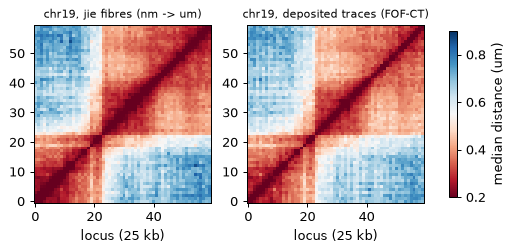

In [8]:
dm_jie = fea.distance_map(cd, "chr19")
ref = ds.load("takei2021_mesc")                  # the deposited traces (4DN FOF-CT), built once
dm_ref = fea.distance_map(ref, "chr19")
iu = np.triu_indices(dm_jie.matrix.shape[0], 1)
r = np.corrcoef(dm_jie.matrix[iu], dm_ref.matrix[iu])[0, 1]
print(f"chr19 median distance maps ({dm_jie.matrix.shape[0]} loci): Pearson r = {r:.3f} "
      f"(jie {dm_jie.n_traces} fibres, FOF-CT {dm_ref.n_traces} traces)")

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, mat, title in [(axes[0], dm_jie.matrix / 1000, "jie fibres (nm -> um)"),
                       (axes[1], dm_ref.matrix, "deposited traces (FOF-CT)")]:
    im = ax.imshow(mat, cmap="RdBu", vmin=0.2, vmax=0.9, origin="lower", interpolation="nearest")
    ax.set_title(f"chr19, {title}", fontsize=9); ax.set_xlabel("locus (25 kb)")
fig.colorbar(im, ax=axes, shrink=0.8, label="median distance (um)")
plt.show()

In [9]:
cd.uns["source"] = "Takei et al. 2021, Zenodo 3735329 (25-kb replicate 1), traced with uchrom.im.trace.align_spots"
cd.write(OUT / "takei2021_jie.chromdata.zarr")    # coordinates in nm (uns["xyz_unit"], kept from the detections)
print("wrote", OUT / "takei2021_jie.chromdata.zarr")

wrote _out/takei2021_jie.chromdata.zarr


## Notes and next steps

- **Parameters matter**: calibrate `max_skip` / `gap_penalty` / `min_spots_per_fiber` to the
  detection efficiency of your data (section 3), ideally against a subset with a trusted
  assignment.  τ is fitted per chromosome when not given.
- jie assumes the genome order is preserved in 3-D chains, so it is blind to structural
  variants (inversions, translocations); sisters closer than the localisation error
  (~150 nm) are merged into one fibre.
- Runtime grows with the candidates per locus; (cell, chromosome) graphs are independent, so
  large data can be split over processes.
- Next: `import_fofct.ipynb` (the traced table of this experiment), `fish_imputation.ipynb`
  (fill the loci a fibre missed), `fishnet_domains.ipynb` / `tad_calling.ipynb` (domains on
  traces).